<a href="https://colab.research.google.com/github/Akila721/aml-colombo-land-price-projection/blob/main/app.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AML Activity — Colombo District Land Price Prediction

**Objective:** Compare Random Forest and XGBoost regressors for estimating advertised land price per perch in Colombo District, Sri Lanka.

This notebook is intentionally commented for learning and review. Run cells in order from a fresh Google Colab runtime.

**Important data caveat:** The dataset appears to be listing/advertisement data, not confirmed completed transactions. The output is an estimate of advertised price per perch, not a professional valuation.

## 1. Install the required libraries

In [16]:
%pip -q install xgboost gradio openpyxl joblib

## 2. Imports and reproducibility


In [17]:
from pathlib import Path
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

RANDOM_STATE = 42
TARGET = "Price per Perch"


## 3. Load the dataset

If the CSV is in the project `data` folder, it is loaded automatically. In Colab, if it is not found, upload `colombo_land_prices.csv` when prompted.

In [18]:
DATA_PATH = Path("data/colombo_land_prices.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise ValueError("Please upload colombo_land_prices.csv.")
        df = pd.read_csv(io.BytesIO(uploaded[csv_names[0]]))
    except ImportError:
        raise FileNotFoundError(
            "Could not find data/colombo_land_prices.csv. Put the CSV in the data folder."
        )

print("Original shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Saving colombo_land_prices.csv to colombo_land_prices (1).csv
Original shape: (4494, 35)


,Address_ID,Address,Land_size(Perches),Price_Scale,Land_type,Posted_Date_new,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,...,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km,Mentioned Price(Rs),Price per Perch
0,6,battaramulla,12.00,per perch,"Commercial, Residential",2021-09-21,11.349555,0,3.099786,3,...,2.966136,0,0.184196,2,0.275528,11,1.185148,2,3800000,3800000.0
1,12,nawala,22.00,per perch,"Commercial, Residential",2021-09-21,9.160830,2,1.530830,12,...,0.885503,5,2.102498,0,0.229320,17,1.221396,4,6500000,6500000.0
2,16,mount lavinia,23.00,per perch,Residential,2021-09-21,12.887396,0,2.727171,5,...,4.077519,0,1.188858,2,0.113300,20,1.052876,5,2600000,2600000.0
3,126,divulpitiya,16.05,per perch,"Commercial, Residential",2021-09-21,12.597925,0,2.631805,2,...,4.266219,0,0.585909,1,0.315818,19,0.523224,3,3700000,3700000.0
4,53,kollupitiya,6.80,per perch,Residential,2021-09-21,4.222136,3,0.838323,8,...,0.744991,4,1.394043,2,0.234181,17,0.836103,4,85000000,85000000.0



Column names:
['Address_ID', 'Address', 'Land_size(Perches)', 'Price_Scale', 'Land_type', 'Posted_Date_new', 'Distance from fort', 'count_govtschools_A', 'min_dist_govtschools_a', 'count_govtschools_B', 'min_dist_govtschools_b', 'count_semigovtschools', 'min_dist_semigovtschools', 'count_intlschools', 'min_dist_intlschools', 'count_uni', 'min_dist_uni', 'min_dist_nearest_express', 'min_dist_nearest_railway', 'min_dist_nearest_bank', 'count_banks_within_2km', 'min_dist_nearest_FinanceCompany', 'count_FinanceCompanies_within_2km', 'min_dist_nearest_Govt_Hospital', 'count_Govt_Hospitals', 'min_dist_nearest_Pvt_Hospital', 'count_Pvt_Hospital', 'min_dist_nearest_Pvt_Med_center', 'count_Pvt_Med_Centers', 'min_dist_nearest_Supermarket', 'count_Supermarkets_within2km', 'min_dist_nearest_Fuel_station', 'count_Fuel_Stations_within2km', 'Mentioned Price(Rs)', 'Price per Perch']


## 4. Inspect data quality

Inspect types, missing values, exact duplicates, target distribution and the date coverage before cleaning.

In [19]:
display(df.info())
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))
print("Exact duplicate rows:", df.duplicated().sum())
print("Target summary:")
display(df[TARGET].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
if "Posted_Date_new" in df.columns:
    dates = pd.to_datetime(df["Posted_Date_new"], errors="coerce")
    print("Posting date range:", dates.min(), "to", dates.max())
    print("Distinct posting dates:", dates.nunique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4494 entries, 0 to 4493
Data columns (total 35 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Address_ID                         4494 non-null   int64  
 1   Address                            4494 non-null   object 
 2   Land_size(Perches)                 4494 non-null   float64
 3   Price_Scale                        4494 non-null   object 
 4   Land_type                          4494 non-null   object 
 5   Posted_Date_new                    4494 non-null   object 
 6   Distance from fort                 4494 non-null   float64
 7   count_govtschools_A                4494 non-null   int64  
 8   min_dist_govtschools_a             4494 non-null   float64
 9   count_govtschools_B                4494 non-null   int64  
 10  min_dist_govtschools_b             4494 non-null   float64
 11  count_semigovtschools              4494 non-null   int64

None

,missing_count
Address_ID,0
Address,0
Land_size(Perches),0
Price_Scale,0
Land_type,0
Posted_Date_new,0
Distance from fort,0
count_govtschools_A,0
min_dist_govtschools_a,0
count_govtschools_B,0


Exact duplicate rows: 177
Target summary:


,Price per Perch
count,4.494000e+03
mean,2.051174e+06
std,3.342610e+06
min,4.600000e+03
1%,1.250000e+05
5%,2.500000e+05
25%,4.500000e+05
50%,9.000000e+05
75%,2.400000e+06
95%,6.500000e+06


Posting date range: 2021-07-31 00:00:00 to 2021-09-21 00:00:00
Distinct posting dates: 53


## 5. Clean duplicate rows and define the target

Exact duplicate rows are removed.

The target is `Price per Perch`. We explicitly exclude `Mentioned Price(Rs)` and `Price_Scale`, because they are directly related to how the target price was recorded and could leak the answer into the model.

In [20]:
before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {before - len(df)} exact duplicate rows.")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()
df = df[df[TARGET] > 0].copy()
print("Shape after duplicate/target cleaning:", df.shape)


Removed 177 exact duplicate rows.
Shape after duplicate/target cleaning: (4317, 35)


## 6. Exploratory data analysis

Land prices are often right-skewed. The plots below help us understand the distribution and variation across land types

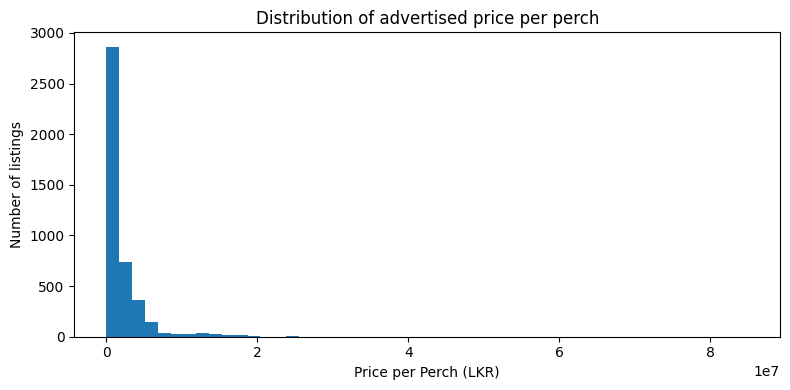

,count,median,mean
Land_type,,,
Residential,2167,9.000000e+05,1.768152e+06
"Commercial, Residential",1060,1.146429e+06,2.795771e+06
"Commercial, Residential, Other",542,8.250000e+05,2.117352e+06
"Residential, Other",256,4.400000e+05,1.158246e+06
Commercial,103,3.000000e+06,4.522344e+06
"Agricultural, Commercial, Residential",78,4.400000e+05,4.733272e+05
"Agricultural, Commercial, Residential, Other",61,9.500000e+05,1.236901e+06
Other,26,4.250000e+06,6.283358e+06
"Commercial, Other",8,5.750000e+06,6.393750e+06


In [21]:
plt.figure(figsize=(8, 4))
plt.hist(df[TARGET], bins=50)
plt.xlabel("Price per Perch (LKR)")
plt.ylabel("Number of listings")
plt.title("Distribution of advertised price per perch")
plt.tight_layout()
plt.show()

if "Land_type" in df.columns:
    display(df.groupby("Land_type")[TARGET].agg(["count", "median", "mean"]).sort_values("count", ascending=False).head(15))


## 7. Feature selection and preprocessing

We remove identifiers, the target, and direct price representation fields

In [22]:
excluded_columns = [
    TARGET,
    "Mentioned Price(Rs)",  # direct target leakage risk
    "Price_Scale",          # related to how the advertised price is represented
    "Address_ID",           # identifier, not a generalizable property feature
    "Posted_Date_new",      # short posting-date window; not used as raw date
]

feature_columns = [c for c in df.columns if c not in excluded_columns]
X = df[feature_columns].copy()
y = df[TARGET].copy()

# Convert date-derived strings/categories consistently if the source contains them.
for col in X.select_dtypes(include=["datetime64[ns]", "datetimetz"]).columns:
    X[col] = X[col].astype(str)

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Feature count:", len(feature_columns))
print("Categorical features:", categorical_features)
print("Numeric features:", len(numeric_features))
print("Excluded columns:", excluded_columns)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=2)),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])


Feature count: 30
Categorical features: ['Address', 'Land_type']
Numeric features: 28
Excluded columns: ['Price per Perch', 'Mentioned Price(Rs)', 'Price_Scale', 'Address_ID', 'Posted_Date_new']


## 8. Train/test split


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))


Training rows: 3453
Test rows: 864


## 9. Configure and train Random Forest and XGBoost

The key hyperparameters are explicitly set rather than relying on default model settings. These are reasonable starting configurations, not guaranteed optimal values. Further tuning should be justified by validation results.

In [24]:
rf_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=350,
        max_depth=18,
        min_samples_split=6,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

xgb_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", XGBRegressor(
        n_estimators=450,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=3,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)
print("Both models trained.")


Both models trained.


## 10. Evaluate and compare

MAE is the average absolute prediction error in LKR per perch. RMSE penalizes large errors more heavily. R² measures improvement over predicting the test-set mean; it can be negative if a model performs poorly.


In [25]:
def evaluate_regressor(name, model, X_eval, y_eval):
    pred = model.predict(X_eval)
    return {
        "Model": name,
        "MAE (LKR/perch)": mean_absolute_error(y_eval, pred),
        "RMSE (LKR/perch)": mean_squared_error(y_eval, pred) ** 0.5,
        "R2": r2_score(y_eval, pred),
    }

results = pd.DataFrame([
    evaluate_regressor("Random Forest", rf_model, X_test, y_test),
    evaluate_regressor("XGBoost", xgb_model, X_test, y_test),
]).sort_values("RMSE (LKR/perch)")
display(results.style.format({
    "MAE (LKR/perch)": "{:,.0f}",
    "RMSE (LKR/perch)": "{:,.0f}",
    "R2": "{:.3f}",
}))


,Model,MAE (LKR/perch),RMSE (LKR/perch),R2
0,Random Forest,"735,782","2,505,276",0.552
1,XGBoost,"735,981","2,541,940",0.539


## 11. Results


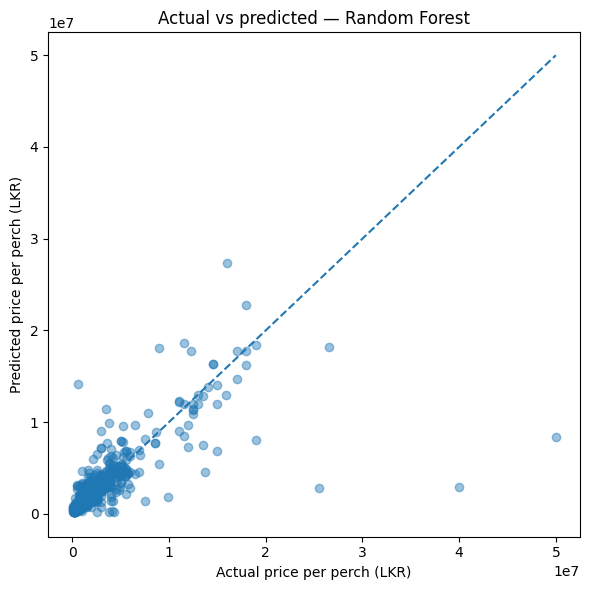

Model selected by lowest test RMSE: Random Forest


In [26]:
# Plot observed vs predicted for the model with lower test RMSE.
best_name = results.iloc[0]["Model"]
best_model = rf_model if best_name == "Random Forest" else xgb_model
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.45)
limit = max(float(y_test.max()), float(best_predictions.max()))
plt.plot([0, limit], [0, limit], linestyle="--")
plt.xlabel("Actual price per perch (LKR)")
plt.ylabel("Predicted price per perch (LKR)")
plt.title(f"Actual vs predicted — {best_name}")
plt.tight_layout()
plt.show()

print("Model selected by lowest test RMSE:", best_name)


## 12. Save the selected pipeline and create the app

The saved pipeline includes preprocessing and the trained model. The frontend loads this file, so its inputs must use the same feature names and compatible values. The selected model is chosen by test RMSE; record that choice and metrics in your submission.

In [27]:
# Refit the selected model on all cleaned labelled data for the final demo model.
# Keep the test-set results above as the reported comparison; the final demo model is refitted for inference.
best_model.fit(X, y)
joblib.dump(best_model, "model.pkl")
print("Saved model pipeline to model.pkl")
print("Selected model:", best_name)


Saved model pipeline to model.pkl
Selected model: Random Forest


## 13. Single-sample inference

One held-out test row to demonstrate inference. This example uses the model fitted before the final refit if available; to keep the demonstration honest, we show prediction and actual value from the test set using the previously trained model. The saved model is intended for the app after the final refit.

In [28]:
# For a clean demonstration of held-out inference, train a demonstration copy on X_train only.
demo_model = rf_model if best_name == "Random Forest" else xgb_model
# Note: best_model has now been refitted on all data, so re-create and fit a fresh demo pipeline.
from sklearn.base import clone
demo_model = clone(rf_model if best_name == "Random Forest" else xgb_model)
demo_model.fit(X_train, y_train)
sample = X_test.iloc[[0]]
actual = float(y_test.iloc[0])
predicted = float(demo_model.predict(sample)[0])
print("Sample input:")
display(sample)
print(f"Actual price per perch: LKR {actual:,.0f}")
print(f"Predicted price per perch: LKR {predicted:,.0f}")
print(f"Absolute error: LKR {abs(actual - predicted):,.0f}")


Sample input:


,Address,Land_size(Perches),Land_type,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,...,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km
3975,nawala,7.65,Residential,9.16083,2,1.53083,12,0.863357,1,0.906167,...,2.580394,0,0.885503,5,2.102498,0,0.22932,17,1.221396,4


Actual price per perch: LKR 2,600,000
Predicted price per perch: LKR 3,637,680
Absolute error: LKR 1,037,680


## 14. Launch the frontend (Gradio)

This creates a temporary public URL for testing. It only works while the Colab runtime is active. The lecturer can run this notebook later in her own Colab session and generate a new link.

The app includes a manual single-property form and a CSV batch-prediction tab.

In [29]:
# Launch Gradio directly inside the notebook.
# This avoids waiting for output from a separate background process.

from pathlib import Path
import importlib
import gradio as gr

assert Path("app.py").exists(), "app.py was not uploaded."
assert Path("model.pkl").exists(), "model.pkl was not generated."

# Import the application without starting a second server.
import app
importlib.reload(app)

# Create a temporary public URL for testing.
demo = app.demo if hasattr(app, "demo") else None

if demo is None:
    raise RuntimeError("Could not find the Gradio interface in app.py.")

demo.launch(
    share=True,
    prevent_thread_lock=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f6479ff9a2c3fc7394.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
